# Assignment 2: Diabetes Classification

**Workflow**

**UNDERSTAND → EDA → SPLIT → PREPARE → FIT → PREDICT → EVALUATE → INTERPRET**

The main idea throughout the notebook is:

**QUESTION → EVIDENCE → DECISION**

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay
)


---
## Step 1 - Understand the data (Kristian)

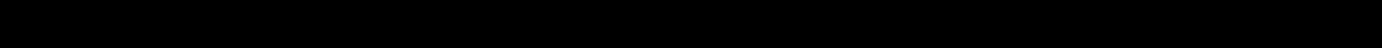


#### Q: Identify the input features X and the target y.

From `Diabetes_Understanding_the_Dataset.docx`, we know that the input X is the 21 features and the target y is `Diabetes_binary`, where 0 = no diabetes & 1 = prediabetes or diabetes.


#### Q: Explain what class 0 and class 1 mean.

As mentioned, class 0 means the respondent has no diabetes, and class 1 means they have _prediabetes_ or _diabetes_. We also see that _prediabetes_ and _diabetes_ both are in class 1, so we can't tell those apart ;(

#### Q: Check the number and proportion of observations in each class.

In [21]:
df = pd.read_csv("Data/diabetes.csv")
target = "Diabetes_binary"

X = df.drop(columns=target)
y = df[target]

print("Shape:", df.shape)
display(df.head())

Shape: (253680, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [22]:
print("Number of observations:")
display(df[target].value_counts()) # number
print("--------------------------")
print("Proportion of observations:")
display(df[target].value_counts(normalize=True)) # proportion

Number of observations:


Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64

--------------------------
Proportion of observations:


Diabetes_binary
0.0    0.860667
1.0    0.139333
Name: proportion, dtype: float64

We see there are 218,334 respondents in class 0 (86.1 %) **don't have diabetes**, and 35,346 in class 1 (13.9 %) either **have _diabetes_ or _prediabetes_**

#### Q: Choose three features of different types and briefly explain what their values mean. Use the Understanding the Dataset guide.

From the dataset guide, section 3 "Complete feature guide", let's pick features `BMI`, `HighBP`, `Age`:

| Feature | Type | What the values mean                                               |
|:---|:---|:-------------------------------------------------------------------|
| `BMI` | Numerical | A measured value, so BMI = 30 is an actual BMI of 30               |
| `HighBP` | Binary | 0 = no and 1 = yes, respondent has high blood pressure             |
| `Age` | Ordinal | An age group, so Age = 9 means 60–64 years old and not 9 years old |

So a number in the CSV isn't always an amount, and we have to check what it means before we use it.

---
## Step 2 - Explore the data (Kristian)


#### For numerical features, examine their distributions and compare them between the two target classes.

The only numerical features listed in "3. Complete feature guide" are `BMI`, `MentHlth` & `PhysHlth`:

In [23]:
numerical_features = ["BMI", "MentHlth", "PhysHlth"]

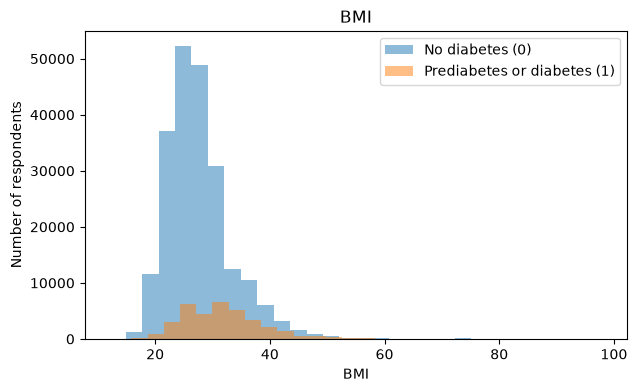

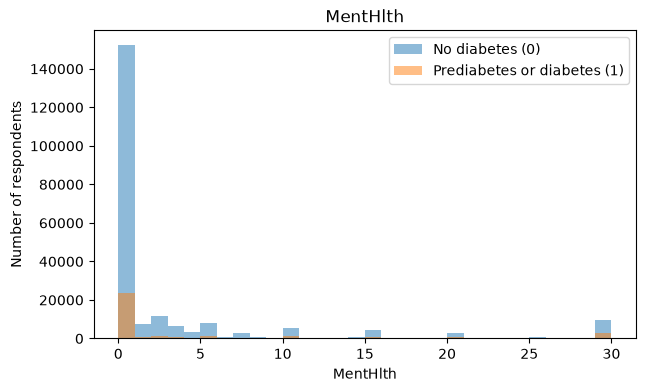

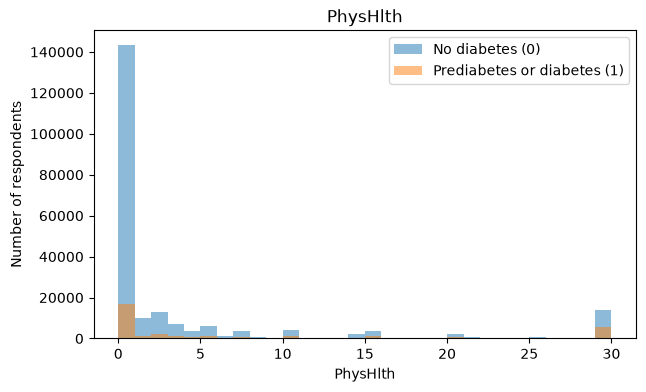

In [24]:
for feature in numerical_features:
    plt.figure(figsize=(7, 4))

    df.loc[df[target] == 0, feature].plot(
        kind="hist", bins=30, alpha=0.5, label="No diabetes (0)"
    )
    df.loc[df[target] == 1, feature].plot(
        kind="hist", bins=30, alpha=0.5, label="Prediabetes or diabetes (1)"
    )

    plt.xlabel(feature)
    plt.ylabel("Number of respondents")
    plt.title(feature)
    plt.legend()
    plt.show()

**What do we see?**

The histograms show that most respondents have a BMI between 20 and 40, and that most have 0 days of poor mental and physical health. Class 1 is quite small compared to class 0, but it looks like class 1 for `BMI` has a peak a bit further to the right, so they tend to have a higher BMI. For `MentHlth` and `PhysHlth` both classes have most respondents at 0 days.

#### For binary categorical features, examine counts/proportions and compare the proportion of Diabetes_binary across the two categories.

First, let's list every binary feature from the dataset guide:

In [25]:
binary_features = [
    "HighBP",
    "HighChol",
    "CholCheck",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "DiffWalk",
    "Sex"
]

Now, let's look at the proportion with diabetes when each binary feature is 0 and when it's 1, using a crosstab for each feature:

,0.0,1.0
HighBP,0.060352,0.244457
HighChol,0.079814,0.220149
CholCheck,0.025449,0.143749
Smoker,0.120553,0.162929
Stroke,0.131798,0.317528
HeartDiseaseorAttack,0.119537,0.329720
PhysActivity,0.211448,0.116127
Fruits,0.157929,0.128609
Veggies,0.179979,0.129887
HvyAlcoholConsump,0.144154,0.058361


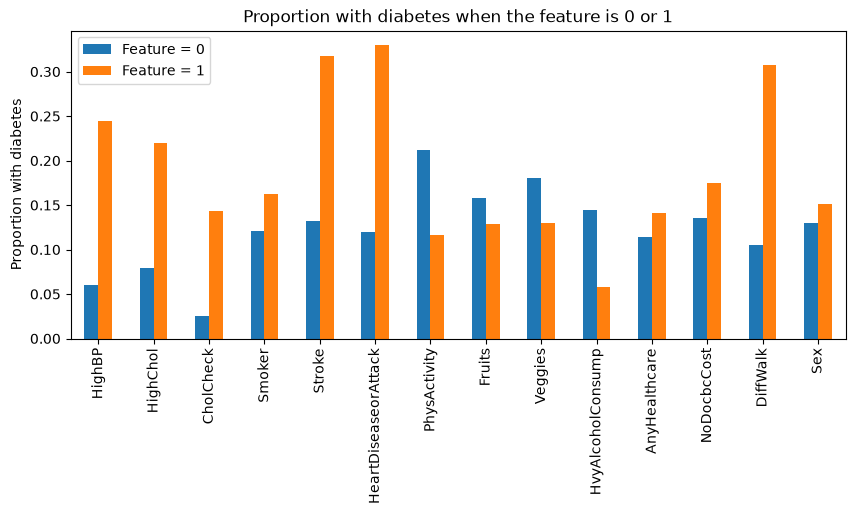

In [26]:
binary_results = {}

for feature in binary_features:
    proportions = pd.crosstab(df[feature], df[target], normalize="index")
    binary_results[feature] = proportions[1.0]

binary_results = pd.DataFrame(binary_results).T
display(binary_results)

binary_results.plot(kind="bar", figsize=(10, 4))
plt.ylabel("Proportion with diabetes")
plt.title("Proportion with diabetes when the feature is 0 or 1")
plt.legend(["Feature = 0", "Feature = 1"])
plt.show()

**What do we see?**

- `HighBP`, `CholCheck`, `HeartDiseaseorAttack` & `DiffWalk` really stand out as the biggest difference, the proportion is around 3-4 times higher when the feature is 1.
- `PhysActivity` and `HvyAlcoholConsump` go the other way, fewer people have diabetes when the feature is 1.
- `Smoker`, `AnyHealthcare`, `NoDocbcCost` & `Sex` show almost no difference.

Note that this is only a pattern in the data, and not the full picture. For example can we see that heavy drinkers have less diabetes, but that doesn't mean alcohol protects against diabetes.

#### For ordered categorical features, examine how the distribution or proportion of Diabetes_binary changes across the ordered categories.

We do the same as last time, but now for ordered (ordinal) features:

In [27]:
ordinal_features = ["GenHlth", "Age", "Education", "Income"]

Unlike the binary features, the ordinal features don't all have the same number of categories, so we can't put them in one table like last time. Instead we make one small plot for each feature:

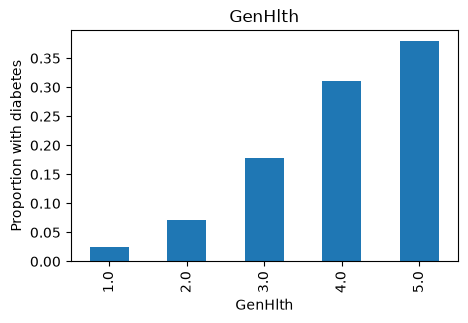

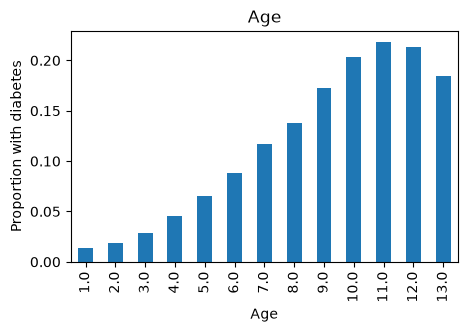

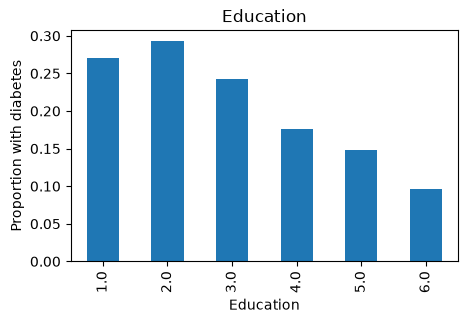

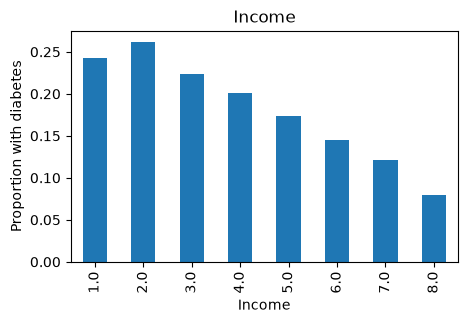

In [28]:
for feature in ordinal_features:
    proportions = pd.crosstab(df[feature], df[target], normalize="index")

    proportions[1].plot(kind="bar", figsize=(5, 3))
    plt.ylabel("Proportion with diabetes")
    plt.title(feature)
    plt.show()

**What do we see?**

- `GenHlth`: the proportion with diabetes goes up with each step, from under 5 % for excellent health (1) to around 40 % for poor health (5).
- `Age`: the proportion goes up with age until about 70-74 (11), then it drops a bit for the oldest groups.
- `Education` & `Income`: the proportion goes down, so higher education and higher income have fewer with diabetes.

So all four ordinal features show a clear pattern across the categories, but again this is only a link and not cause and effect.

#### Explore all input features, but focus your detailed interpretation on the most informative or interesting results. You may use loops or functions where appropriate rather than repeating essentially identical code.

We have looked at all the (3 + 14 + 4) 21 input features above. The most interesting results are:

- `HvyAlcoholConsump`: heavy drinkers have fewer with diabetes, which is the opposite of what we might expect.
- `CholCheck`: those who have checked their cholesterol have more with diabetes... could be because people with diabetes see a doctor more often.
- `GenHlth`: the proportion of people with diabetes increases quite steadily the worse their health is.
- `Age`: diabetes amount goes up with age, but drops for ages 80+... maybe fewer with diabetes live that long (?).
- `Smoker`, `Sex` & `MentHlth` show almost no difference, even though we might expect smoking to matter.

#### For the results you discuss in detail, state the question, show appropriate evidence, explain what you observe, and explain what the evidence allows you to conclude and what it does not.

For `HvyAlcoholConsump` we wanted to see if heavy drinkers have more diabetes. The binary table shows the opposite, non-heavy drinkers have about 2-3 times more people with diabetes than heavy drinkers. So in this dataset heavy drinking is linked to fewer with diabetes, but we can't really say that alcohol prevents it. People with diabetes might just be told to stop drinking.

For `GenHlth`, people with poor health have more than 10 times more diabetes than those with excellent health, so this one looks really useful for the model. But that doesn't mean poor health causes diabetes, it might as well be the other way around.

#### Look for patterns such as differences between the two target classes, changes in the proportion of class 1 across categories, unusual distributions, and features that appear to have little relationship with the target.

Most of this has already been covered above, but one thing we haven't mentioned is that `MentHlth` & `PhysHlth` look a bit weird. Most people answer 0 days, but there are peaks at 5, 10, 15 and 30, probably because people like round numbers, and choose numbers like 5 or 15 instead of the exact number of days.

---
## Step 3 - Create TRAIN and TEST (Emilie)

#### Split X and y into TRAIN and TEST.

#### Use stratify=y so that TRAIN and TEST have approximately the same proportion of class 0 and class 1.

#### Keep TEST separate until evaluation. Do not balance or resample TEST.

In [29]:
# Splitting of the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y, # Uses stratify so both the train and test are representable.
    random_state=42
)

# Prints the whole dataset, the train anf the test set to check if they are kinda similar.
print("The whole dataset:")
print(y.value_counts(normalize=True))
print("TRAIN:")
print(y_train.value_counts(normalize=True))
print("TEST:")
print(y_test.value_counts(normalize=True))

The whole dataset:
Diabetes_binary
0.0    0.860667
1.0    0.139333
Name: proportion, dtype: float64
TRAIN:
Diabetes_binary
0.0    0.860666
1.0    0.139334
Name: proportion, dtype: float64
TEST:
Diabetes_binary
0.0    0.860671
1.0    0.139329
Name: proportion, dtype: float64


---
## Step 4 - Prepare the features (Kristian)

#### Q: Prepare the input features using the information in the Understanding the Dataset guide and the preprocessing methods introduced in the course. Your preprocessing choice should reflect whether a feature is numerical, binary categorical, or ordered categorical. Briefly justify how you represent each type.

From the dataset guide (section 5), we know that all columns are stored as numbers, but they don't all represent numerical measurements:

- **Binary** (the 14 yes/no features): already 0/1, so we just keep them.
- **Ordinal** (`Age`, `Education`, `Income`, `GenHlth`): ordered groups, not measured distances, so we use `OrdinalEncoder`.
- **Numerical** (`BMI`, `MentHlth`, `PhysHlth`): real measurements and counts of days, so we scale them with `StandardScaler`.

Because the ordinal categories are in order, they are not nominal, which means we can use ordinal encoding and not One-Hot. The binary ones are already 0/1, so they don't need One-Hot either. The numerical ones aren't categories at all, so they don't need any encoding, we just scale them.

Now we put this into a ColumnTransformer, so each type gets its own preprocessing. The order for the ordinal features comes from section 3 in the dataset guide:

In [30]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", StandardScaler(), numerical_features),

        ("ordinal",
         OrdinalEncoder(categories=[
             [1, 2, 3, 4, 5],  # GenHlth
             [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13], # Age
             [1, 2, 3, 4, 5, 6], # Education
             [1, 2, 3, 4, 5, 6, 7, 8] # Income
         ]),
         ordinal_features)
    ],
    remainder="passthrough" # binary features
)

In [31]:
model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

Nothing is learned yet, we've only made the recipe. When we fit the model in step 5, the scaler learns the mean and standard deviation from TRAIN only, and TEST just uses those same numbers afterwards.

---
## Step 5 - Train logicstic regression (David)

#### Use Logistic Regression, as introduced in the classification lecture. Fit the complete Pipeline using TRAIN.

As explained in the lecture and in the lecture notes, Logistic Regression is a classification algorithm, despite its name. It gives each input feature a weight and combines them into a score, and the logistic function then turns that score into a probability between 0 and 1, which we read as P(diabetes = 1 | X).

Now we fit the whole Pipeline from step 4 on TRAIN only. `fit()` does two things:
- the preprocessor learns only from `X_train` (the StandardScaler learns the mean and standard deviation of `BMI`, `MentHlth` and `PhysHlth`)
- Logistic Regression learns one coefficient per feature, and an intercept from the prepared `X_train` together with `y_train`

In [32]:
model.fit(X_train, y_train)

scaler = model.named_steps["preprocess"].named_transformers_["numerical"]

display(pd.DataFrame({
    "TRAIN mean": scaler.mean_,
    "TRAIN std": np.sqrt(scaler.var_)
}, index=numerical_features).round(2))

,TRAIN mean,TRAIN std
BMI,28.38,6.60
MentHlth,3.19,7.42
PhysHlth,4.25,8.73


The scaler has learned the mean and standard deviation from the TRAIN data. The table only shows `BMI`, `MentHlth` and `PhysHlth`, because these are the only features that are scaled. The 4 ordinal features are ordinal-encoded, and the 14 binary features are passed through unchanged as 0/1, as described in step 4.

 When we later use the model on TEST, these same TRAIN numbers are used to scale TEST, so nothing is learned from TEST, described in the dataset guide section 8: *"Learn any data-dependent preprocessing and model parameters from TRAIN only"*.

#### Use model.predict(X_test) to obtain predicted classes.

In [33]:
y_pred = model.predict(X_test)

print("Predicted classes on TEST:")
print(pd.Series(y_pred).value_counts())

Predicted classes on TEST:
0.0    48563
1.0     2173
Name: count, dtype: int64


`predict()` gives a final class, 0 or 1, for every respondent in TEST, which is the model's guess of `Diabetes_binary` without knowing the answer `y_test`. It uses the default rule where the probability of class 1 is 0.50 or more, then predict 1, otherwise predict 0.

As we can see, the model predicts only 2,173 as class 1. We know from the split that about 7,069 respondents in TEST are actually class 1, so the model seems to predict class 1 too rarely.

#### Use model.predict_proba(X_test)[:, 1] to obtain predicted probabilities for class 1.

`predict()` only gave us the final class (0 or 1) the model decided on. Here we look at the probability behind that decision. `predict_proba()` gives two probabilities for each respondent, one for class 0 and one for class 1. `model.classes_` shows the order is `[0, 1]`, so `[:, 1]` picks the probability of class 1 = prediabetes or diabetes.

In [34]:
y_probability = model.predict_proba(X_test)[:, 1]

print("Class order:", model.classes_)

preview = pd.DataFrame({
    "actual": y_test.to_numpy()[:10],
    "predicted_probability_class_1": y_probability[:10],
    "predicted_class": y_pred[:10]
})

print(preview.round(3))

Class order: [0. 1.]
   actual  predicted_probability_class_1  predicted_class
0     0.0                          0.154              0.0
1     1.0                          0.292              0.0
2     0.0                          0.020              0.0
3     0.0                          0.033              0.0
4     1.0                          0.481              0.0
5     0.0                          0.119              0.0
6     0.0                          0.029              0.0
7     0.0                          0.011              0.0
8     0.0                          0.053              0.0
9     0.0                          0.167              0.0


A probability is not yet a class. As described in the lecture and in the dataset guide section 7, a threshold is needed to turn it into 0 or 1. The `predicted_class` column is the same as `y_pred`. `predict()` got it by taking the probability and applying a threshold of 0.50, as explained over.

For example, row 4 is actually class 1 and gets a probability of 0.481. That is just under 0.50, so it is predicted as class 0, which makes it a missed case. Row 1 is also actually class 1, but gets only 0.292. This shows why the threshold matters.

---
## Step 6 - Evaluate the model (David)

Now, we are going to evaluate the Logistic Regression model on TEST.

#### Confusion matrix:

We start with the confusion matrix, because it shows what kinds of mistakes the model makes, not only how many. Positive class = 1 (prediabetes or diabetes). We compare the model's guesses `y_pred` with the answer key `y_test`.

TN = 42616
FP = 1051
FN = 5947
TP = 1122


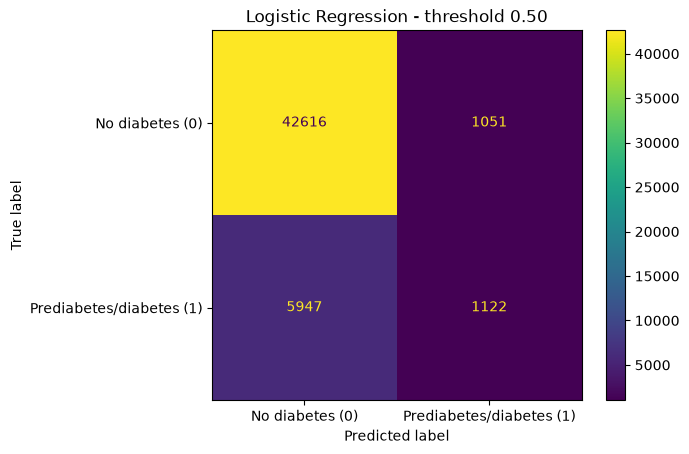

In [35]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print("TN =", tn)   #True negative
print("FP =", fp)   #False positive
print("FN =", fn)   #False negative
print("TP =", tp)   #True positive

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No diabetes (0)", "Prediabetes/diabetes (1)"]
).plot()

plt.title("Logistic Regression - threshold 0.50")
plt.show()


- **TN = 42,616**: no diabetes, and the model said no diabetes ✓
- **TP = 1,122**: diabetes, and the model said diabetes ✓
- **FP = 1,051**: no diabetes, but the model said diabetes ✗ (false alarm)
- **FN = 5,947**: diabetes, but the model said no diabetes ✗ (missed case)

Out of the 7,069 respondents in TEST who actually are class 1, the model only finds 1,122 and misses 5,947.

#### Accuracy, Precision, Recall and F1 score:

In [36]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", round(accuracy, 3))

precision = precision_score(y_test, y_pred)
print("Precision:", round(precision, 3))

recall = recall_score(y_test, y_pred)
print("Recall:", round(recall, 3))

f1 = f1_score(y_test, y_pred)
print("F1:", round(f1, 3))

Accuracy: 0.862
Precision: 0.516
Recall: 0.159
F1: 0.243


**Accuracy** = (TP + TN) / all = 0.862, so the model is correct for 86.2 % of the respondents in TEST.

This sounds good, but 86.1 % of TEST is class 0. A "model" that just says "no diabetes" for everyone would get almost the same accuracy (0.861) while finding zero diabetes cases. With an imbalanced target, high accuracy can hide poor detection of class 1, explained in the dataset guide section 7.

**Precision** = TP / (TP + FP) = 1,122 / 2,173 = 0.516.

Of the respondents the model flagged as class 1, about half actually are class 1.

**Recall** = TP / (TP + FN) = 1,122 / 7,069 = 0.159.

Of the respondents who actually are class 1, the model finds only about 16 %, and misses about 84 %. This is a very weak part of the model, where people who actually have prediabetes or diabetes, are not detected by the model.

**F1 score** = 2 × (precision × recall) / (precision + recall) = 0.243.

F1 combines precision and recall into one number at this threshold. It is low because recall is very low. F1 summarizes the two metrics, but does not replace looking at them separately.

#### Explain what a false positive and a false negative mean for this diabetes classification problem. Do not judge the model from accuracy alone.

- **False positive (FP = 1,051):** a respondent without diabetes is predicted as having prediabetes or diabetes. The consequence could be unnecessary worry and follow up tests.
- **False negative (FN = 5,947):** a respondent with prediabetes or diabetes is predicted as having no diabetes. The consequence could be that the person is not followed up, and misses early lifestyle changes or treatment.

Therefore, a missed case (FN) is usually seen as the more serious mistake, and our model makes far more FN than FP. So even though accuracy is 0.862, the model misses most of the people we would want to find. This is why we cannot judge the model from accuracy alone.

---
## Step 7 - Probability and threshold (Emilie)

#### Use the predicted probabilities from Logistic Regression to compare two decision thresholds: 0.50 and 0.40.

In [37]:
y_pred_040 = (y_probability >= 0.40).astype(int)

cm_040 = confusion_matrix(y_test, y_pred_040)
tn_040, fp_040, fn_040, tp_040 = cm_040.ravel()

precision_040 = precision_score(y_test, y_pred_040)
recall_040 = recall_score(y_test, y_pred_040)

print("TN =", tn_040)
print("FP =", fp_040)
print("FN =", fn_040)
print("TP =", tp_040)
print("Precision:", round(precision_040, 3))
print("Recall:", round(recall_040, 3))

TN = 41542
FP = 2125
FN = 5161
TP = 1908
Precision: 0.473
Recall: 0.27


Next, the confusion matrixes of Threshold value 0.4 and 0.5 are being compared. The confusion matrix for 0.5 are being reused from step 6.

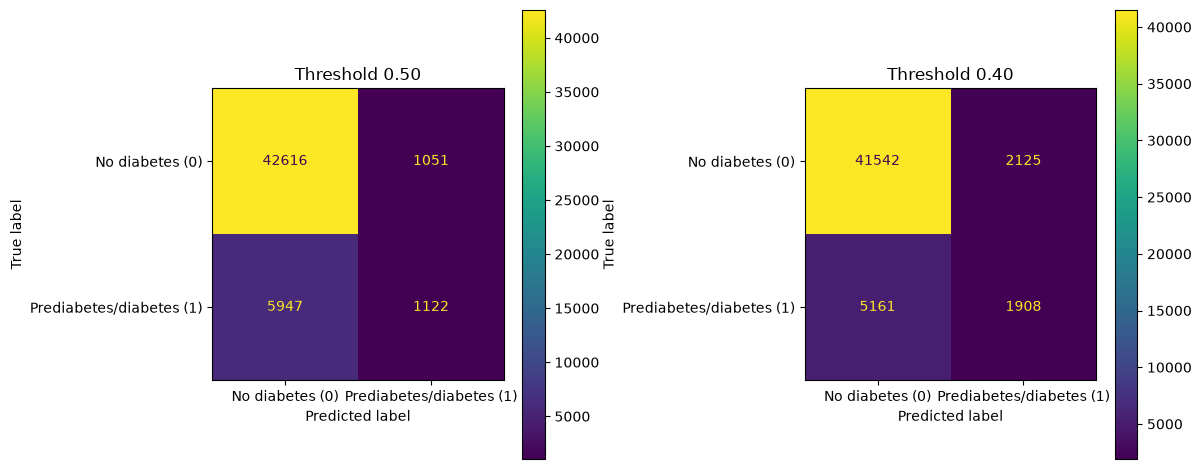

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
labels = ["No diabetes (0)", "Prediabetes/diabetes (1)"]

ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=axes[0])
axes[0].set_title("Threshold 0.50")

ConfusionMatrixDisplay(cm_040, display_labels=labels).plot(ax=axes[1])
axes[1].set_title("Threshold 0.40")

plt.tight_layout()
plt.show()

#### For each threshold, calculate the confusion matrix, precision and recall.

The confusion matrix for the 0.4 threshold shows a decreasing in False Negatives by 786 persons which is better results. This is the section we want to minimize. The True Negative has also decreased. While the false positive and true positive increased. This is because a lower threshold makes the model flag more people as class 1.

The precision of the 0.4 threshold is 0.473, while for the 0.5 threshold it is 0.516. This means that a smaller share of the people the model flags as class 1 actually have prediabetes or diabetes. With the lower threshold the model gives more false alarms, because it also flags more people who are healthy.

The recall of the 0.4 threshold is 0.27, vile the 0.5 threshold it is 0.159. This means that the model now finds 27 % of the people who actually have prediabetes or diabetes, compared to 16 % before. It detects 786 more of them, but it still misses about 73 %, so recall is still low.


#### Compare the results. Explain what happened to false positives, false negatives, precision and recall.

#### Also explain what did NOT change when you changed only the threshold.

The model, the predicted probabilities and the TEST data are the same. The number of actual class 0 respondents is still 43,667 (TN + FP = 42,616 + 1,051 = 41,542 + 2,125) and class 1 is still 7,069 (FN + TP = 5,947 + 1,122 = 5,161 + 1,908). Only the cut-off changed, so respondents just moved between the boxes: 786 respondents moved from FN to TP, and 1,074 moved from TN to FP. The model did not become better at recognizing diabetes, we only traded fewer missed cases for more false alarms.

---
## Step 8 - Conclusion (Emilie)

#### Summarize the most important things you learned from the EDA and the Logistic Regression results.

#### Give at least two limitations of this analysis.

#### Do not interpret an association as evidence that one feature causes diabetes.